# Assignment 5: Visual Exploration and Interactive Dashboards

**Name: ANJALI VERMA **  
 **Roll No.: 2503203100020 **
 



## Setup and dataset
This cell recreates the **exact seeded dataset** given in the assignment. No external CSV is needed.

In [51]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

np.random.seed(7)

dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
cities = ["Delhi", "Mumbai", "Bengaluru"]
categories = ["Electronics", "Clothing", "Grocery"]

df = pd.DataFrame(
    [(d, c, k) for d in dates for c in cities for k in categories],
    columns=["Date", "City", "Category"]
)

base = {"Electronics": 400, "Clothing": 250, "Grocery": 150}
n = len(df)

df["Discount"] = np.random.choice([0, 5, 10, 15, 20], n)

trend = 1 + df["Date"].dt.day_of_year / 365 * 0.3
weekend = np.where(df["Date"].dt.day_of_week >= 5, 1.25, 1.0)
festive = np.where(df["Date"].dt.month.isin([10, 11]), 1.3, 1.0)
city_factor = df["City"].map({
    "Delhi": 1.0,
    "Mumbai": 1.15,
    "Bengaluru": 0.9
})

df["Revenue"] = (
    df["Category"].map(base) * trend * weekend *
    festive * city_factor * (1 + df["Discount"] / 100) *
    np.random.normal(1, 0.08, n)
).round(1)

df.loc[[100, 1502, 2801], "Revenue"] *= 8

print(df.head())

        Date    City     Category  Discount  Revenue
0 2025-01-01   Delhi  Electronics        20    427.1
1 2025-01-01   Delhi     Clothing         5    223.7
2 2025-01-01   Delhi      Grocery        15    143.1
3 2025-01-01  Mumbai  Electronics        15    512.0
4 2025-01-01  Mumbai     Clothing        20    409.8


## Part A — Visual Exploration

### Task 1: First look at the data

In [52]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

df["Month"] = df["Date"].dt.month
df["Weekday"] = df["Date"].dt.day_of_week

print("\nTotal Rows:", len(df))
print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())

print("\nFirst 5 Rows:")
print(df.head())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3285 entries, 0 to 3284
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      3285 non-null   datetime64[us]
 1   City      3285 non-null   str           
 2   Category  3285 non-null   str           
 3   Discount  3285 non-null   int64         
 4   Revenue   3285 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 128.4 KB

Statistical Summary:
                      Date     Discount      Revenue
count                 3285  3285.000000  3285.000000
mean   2025-07-02 00:00:00     9.785388   388.562466
min    2025-01-01 00:00:00     0.000000   122.300000
25%    2025-04-02 00:00:00     5.000000   238.400000
50%    2025-07-02 00:00:00    10.000000   350.800000
75%    2025-10-01 00:00:00    15.000000   501.500000
max    2025-12-31 00:00:00    20.000000  2883.200000
std                    NaN     7.0413

**Written answer:** There are **3,285 rows**, covering **1 January 2025 to 31 December 2025**. No values are missing. `Month` (1–12) and `Weekday` (0=Monday through 6=Sunday) have been added.

### Task 2: Trend over the year

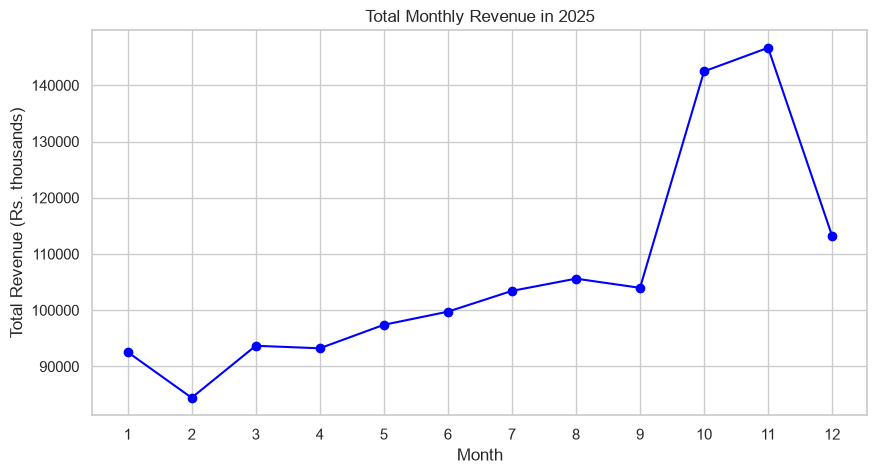

Highest Month: 11
Lowest Month: 2


In [53]:

monthly_revenue = df.groupby("Month")["Revenue"].sum()

plt.figure(figsize=(10, 5))
monthly_revenue.plot(marker="o", color="blue")

plt.title("Total Monthly Revenue in 2025")
plt.xlabel("Month")
plt.ylabel("Total Revenue (Rs. thousands)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

print("Highest Month:", monthly_revenue.idxmax())
print("Lowest Month:", monthly_revenue.idxmin())


**Written answer:** **November** has the highest monthly total (₹146,668.1 thousand), while **February** has the lowest (₹84,433.7 thousand). The upward yearly trend and the extra festive-season multiplier in October–November help explain the rise. The three extreme values can also affect raw totals.

### Task 3: Pattern across the week

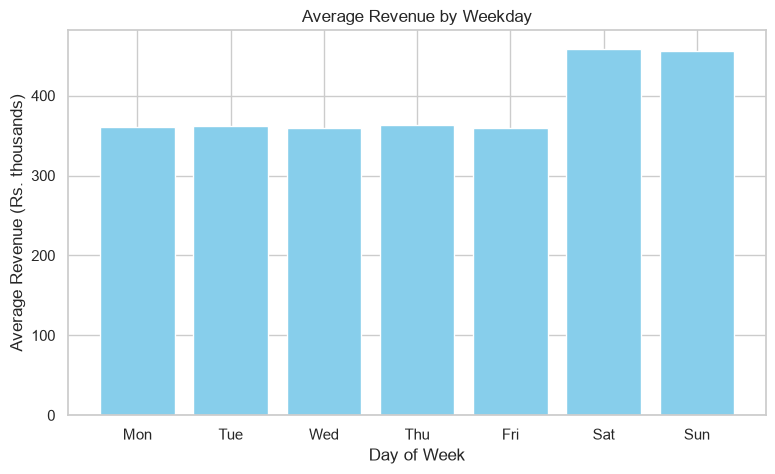

Weekday
0    361.200855
1    362.054701
2    359.485954
3    363.636111
4    359.530769
5    458.784829
6    455.803205
Name: Revenue, dtype: float64


In [54]:

weekday_revenue = df.groupby("Weekday")["Revenue"].mean()

plt.figure(figsize=(9, 5))
plt.bar(weekday_revenue.index, weekday_revenue.values,
        color="skyblue")

plt.title("Average Revenue by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Revenue (Rs. thousands)")

plt.xticks(range(7),
           ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])

plt.show()

print(weekday_revenue)

**Written answer:** Weekend days generally earn more because the dataset applies a 25% weekend boost. Average Saturday/Sunday revenue is **₹457.3 thousand**, compared with **₹361.2 thousand** on weekdays (about **26.6% higher**).

### Task 4: City and category pattern

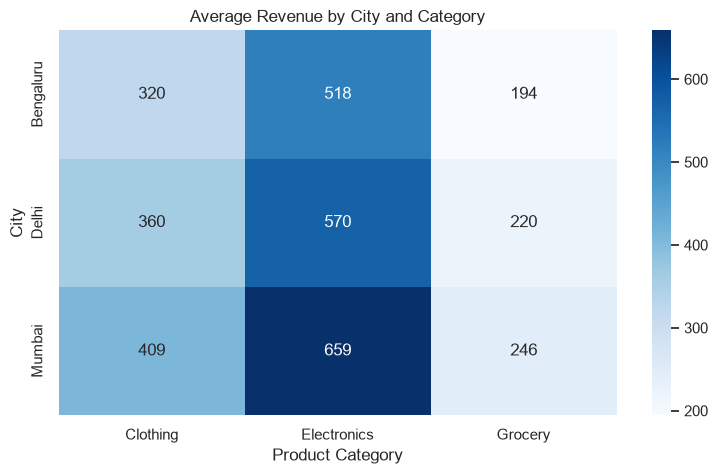

Category     Clothing  Electronics     Grocery
City                                          
Bengaluru  320.240274   518.329589  194.473425
Delhi      360.089315   570.018082  220.158356
Mumbai     408.540548   658.990137  246.222466


In [55]:
pv = df.pivot_table(
    index="City",
    columns="Category",
    values="Revenue",
    aggfunc="mean"
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    pv,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Average Revenue by City and Category")
plt.xlabel("Product Category")
plt.ylabel("City")
plt.show()

print(pv)

**Written answer:** **Mumbai** has the highest overall average revenue. The category order is the same in all three cities: **Electronics > Clothing > Grocery**.

### Task 5: Discount and revenue

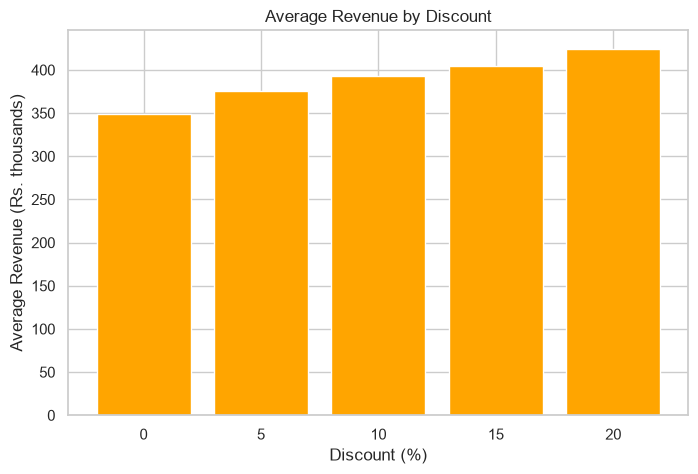

Discount
0     349.337263
5     375.684533
10    392.455111
15    404.568043
20    424.701786
Name: Revenue, dtype: float64


In [56]:
discount_revenue = df.groupby("Discount")["Revenue"].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    discount_revenue.index.astype(str),
    discount_revenue.values,
    color="orange"
)

plt.title("Average Revenue by Discount")
plt.xlabel("Discount (%)")
plt.ylabel("Average Revenue (Rs. thousands)")
plt.show()

print(discount_revenue)

**Written answer:** A larger discount generally goes with higher revenue in this simulated dataset: the mean is **₹349.3 thousand** at 0% versus **₹424.7 thousand** at 20%. The observed rise is **not perfectly steady** because of random variation, mixed categories, and outliers; this does not prove discounts cause additional sales.

### Task 6: Finding and handling outliers

In [57]:
fig = px.box(
    df,
    x="Category",
    y="Revenue",
    hover_data=["Date", "City"],
    title="Revenue Outlier Detection"
)

fig.update_layout(
    xaxis_title="Product Category",
    yaxis_title="Revenue (Rs. thousands)"
)

fig.show()

# Identify the three extreme outliers
outliers = df.loc[[100, 1502, 2801],
                  ["Date", "City", "Category", "Revenue"]]

print("Three Unusual Values:")
print(outliers)

# Remove outliers
category_mean = df.groupby("Category")["Revenue"].transform("mean")

clean = df[df["Revenue"] <= 3 * category_mean].copy()

print("Rows Removed:", len(df) - len(clean))
print("Clean Dataset Rows:", len(clean))

Three Unusual Values:
           Date       City  Category  Revenue
100  2025-01-12      Delhi  Clothing   2883.2
1502 2025-06-16  Bengaluru   Grocery   1061.6
2801 2025-11-08      Delhi   Grocery   2779.2
Rows Removed: 3
Clean Dataset Rows: 3282


**Three extreme values** (revenue in ₹ thousands):

| Date | City | Category | Revenue |
|---|---|---|---:|
| 2025-01-12 | Delhi | Clothing | 2,883.2 |
| 2025-06-16 | Bengaluru | Grocery | 1,061.6 |
| 2025-11-08 | Delhi | Grocery | 2,779.2 |

**Other dots above the whiskers:** Seasonal, weekend and festive demand can produce legitimate high-revenue days, so not every high observation is an error.

**Why investigate before deleting?** A large value could be a real business event, and deleting it without checking could hide important information.

**Cleaning result:** Exactly **3 rows** are removed; the remaining **3,282 rows** are used for Part B.

## Part B — Interactive Dashboard
All charts below use the cleaned `clean` DataFrame.

### Task 7: Four interactive charts

In [58]:
monthly = clean.groupby(
    ["Month", "City"], as_index=False
)["Revenue"].sum()

fig_a = px.line(
    monthly,
    x="Month",
    y="Revenue",
    color="City",
    markers=True,
    title="Monthly Revenue by City"
)

fig_a.update_layout(
    xaxis_title="Month",
    yaxis_title="Revenue (Rs. thousands)"
)

fig_a.show()

#PART B:TOTAL REVENUE

category_sales = clean.groupby(
    "Category", as_index=False
)["Revenue"].sum()

fig_b = px.bar(
    category_sales,
    x="Category",
    y="Revenue",
    color="Category",
    title="Total Revenue by Category"
)

fig_b.update_layout(
    xaxis_title="Category",
    yaxis_title="Revenue (Rs. thousands)"
)

fig_b.show()

#PART3:CITY VS CATEGORY HEATMAP


pv_clean = clean.pivot_table(
    index="City",
    columns="Category",
    values="Revenue",
    aggfunc="mean"
)

fig_c = px.imshow(
    pv_clean,
    text_auto=".0f",
    color_continuous_scale="Blues",
    title="Average Revenue: City vs Category"
)

fig_c.update_layout(
    xaxis_title="Category",
    yaxis_title="City"
)

fig_c.show()

#PART4:AVERAGE REVENUE BY DISCOUNT


discount_sales = clean.groupby(
    "Discount", as_index=False
)["Revenue"].mean()

fig_d = px.bar(
    discount_sales,
    x="Discount",
    y="Revenue",
    title="Average Revenue by Discount (%)"
)

fig_d.update_layout(
    xaxis_title="Discount (%)",
    yaxis_title="Average Revenue (Rs. thousands)"
)

fig_d.show()


**Written answer:** The city lines show seasonal and year-end changes, the category chart compares overall contribution, the heatmap shows the city/category mix, and the discount chart shows average revenue at each discount level. Hover over values, zoom, and click legend items to explore.

### Task 8: Combine the charts into a 2 × 2 dashboard

In [59]:
from plotly.subplots import make_subplots

dash = make_subplots(
    rows=2,
    cols=2,
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "heatmap"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "Monthly Revenue by City",
        "Total Revenue by Category",
        "Average Revenue: City vs Category",
        "Average Revenue by Discount (%)"
    )
)

for trace in fig_a.data:
    dash.add_trace(trace, row=1, col=1)

for trace in fig_b.data:
    dash.add_trace(trace, row=1, col=2)

for trace in fig_c.data:
    dash.add_trace(trace, row=2, col=1)

for trace in fig_d.data:
    dash.add_trace(trace, row=2, col=2)

dash.update_coloraxes(showscale=False)

dash.update_layout(
    height=800,
    title_text="Retail Sales Dashboard",
    template="simple_white",
    barmode="group"
)

dash.update_xaxes(title_text="Month", row=1, col=1)
dash.update_yaxes(
    title_text="Revenue (Rs. thousands)",
    row=1, col=1
)

dash.update_xaxes(title_text="Category", row=1, col=2)
dash.update_yaxes(
    title_text="Revenue (Rs. thousands)",
    row=1, col=2
)

dash.update_xaxes(title_text="Category", row=2, col=1)
dash.update_yaxes(title_text="City", row=2, col=1)

dash.update_xaxes(title_text="Discount (%)", row=2, col=2)
dash.update_yaxes(
    title_text="Avg Revenue (Rs. thousands)",
    row=2, col=2
)

dash.show()

dash.write_html(
    "sales_dashboard.html",
    include_plotlyjs="cdn",
    full_html=True
)

print("Dashboard saved successfully!")

Dashboard saved successfully!


**Written answer:** The dashboard combines all four interactive charts into one 2 × 2 view. The standalone `sales_dashboard.html` includes Plotly JavaScript and can be opened offline in a browser. The monthly chart legend lets you show or hide cities.

**Optional bonus:** Not used; the required four panels are retained.

## Part C — Task 9: One-page visual report for stakeholders

In [60]:
monthly_clean = clean.groupby("Month")["Revenue"].sum()
city_clean = clean.groupby("City")["Revenue"].sum()
category_clean = clean.groupby("Category")["Revenue"].sum()

print("Highest Revenue Month:",
      monthly_clean.idxmax(),
      round(monthly_clean.max(), 2))

print("Lowest Revenue Month:",
      monthly_clean.idxmin(),
      round(monthly_clean.min(), 2))

print("Best Performing City:",
      city_clean.idxmax(),
      round(city_clean.max(), 2))

print("Top Category:",
      category_clean.idxmax(),
      round(category_clean.max(), 2))

print("Outliers Removed:", len(df) - len(clean))

Highest Revenue Month: 11 143888.9
Lowest Revenue Month: 2 84433.7
Best Performing City: Mumbai 479519.9
Top Category: Electronics 637778.3
Outliers Removed: 3


# Retail Sales Performance Report — 2025

**Purpose:** Review retail revenue across Delhi, Mumbai and Bengaluru during 2025 and suggest practical steps for the store manager. All money figures are in **₹ thousands**.

### Three key findings

1. **Mumbai** generated the most total revenue, at **₹479,519.9 thousand**, after cleaning.
2. **Electronics** was the strongest category, bringing in **₹637,778.3 thousand** across all cities.
3. Weekend average revenue was **₹452.2 thousand** per record versus **₹360.9 thousand** on weekdays — approximately **25.3% higher**.

### Data quality note

Three unusually large revenue records were found (on **2025-01-12, 2025-06-16, 2025-11-08**). They were excluded using the assignment's threshold of three times the category mean, leaving **3,282** records for dashboard analysis. In a real business setting, these sales should be checked against source records before permanent removal.

### Two recommendations

1. **Prepare for busy weekends and festive periods:** Schedule enough staff and stock, particularly for Electronics, before demand rises.
2. **Use city- and category-level insights:** Review what drives Mumbai's stronger performance, and test targeted promotions rather than assuming bigger discounts always improve results.

**Note:** The dataset is simulated; observed patterns are useful for this exercise but should not be treated as proven causal effects.